### ***Setup***

In [14]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from collections import namedtuple


# Simple plotting
plt.rcParams['figure.figsize'] = (8,5)
plt.rcParams['font.size'] = 12


# Tolerances required
TOL_F = 1e-8
TOL_X = 1e-10
MAX_IT = 200


# A tiny value to avoid division by zero
TINY = 1e-14


# A small convenience namedtuple for results
Result = namedtuple('Result', ['root','iters','history','extra'])



### ***Functions under test***

In [ ]:
# Provided functions and their derivatives

def f1(x):
 return x**3 + x - 3


def df1(x):
 return 3*x**2 + 1


def f2(x):
 return math.cos(x) - x


def df2(x):
 return -math.sin(x) - 1


import math as _m


def f3(x):
 return x * math.exp(-x) - 0.1


def df3(x):
 return math.exp(-x) * (1 - x)


def f4(x):
 return x**3 - 2*x**2 - 5


def df4(x):
 return 3*x**2 - 4*x


def f5(x):
 return (x - 1)**2 * (x + 2) # multiple root at x = 1


def df5(x):
 return 2*(x-1)*(x+2) + (x-1)**2


def f6(x):
# Use numpy's cbrt for real cube root
 return np.cbrt(x)


# Derivative blows up near 0; we won't use df6 directly


def df6(x):
# analytic derivative for cube-root: (1/3) * x^{-2/3} but undefined at 0
 if x == 0:
  return float('inf')
 return (1.0/3.0) * (abs(x) ** (-2.0/3.0))


# f7: my choice (continuous, nontrivial): f7(x) = x + sin(x) - 1
# Root near x=0.5 because 0.5 + sin(0.5) - 1 ~ 0.0


def f7(x):
 return x + math.sin(x) - 1


def df7(x):
 return 1 + math.cos(x)


# Put the functions and intervals in a list for easy looping
functions = [
(f1, df1, [0,4], 'f1: x^3 + x - 3'),
(f2, df2, [0,1], 'f2: cos(x) - x'),
(f3, df3, [0,2], 'f3: x e^{-x} - 0.1'),
(f4, df4, [2,4], 'f4: x^3 - 2x^2 - 5'),
(f5, df5, [-3,0], 'f5: (x-1)^2 (x+2) [left bracket]'),
(f5, df5, [0,3], 'f5: (x-1)^2 (x+2) [right bracket]'),
(f6, df6, [-1e-3, 1e-3], 'f6: cbrt(x) small bracket around 0'),
(f7, df7, [0,1], 'f7: x + sin(x) - 1')
]



## Q1: IVT & Bracketing Warm-***Up***

In [15]:
# For each of f1-f5 check f(a) and f(b) and sign change
print('Q1: IVT checks (show f(a) and f(b))')
for (f, df, interval, name) in functions[:6]:
 a, b = interval
fa, fb = f(a), f(b)
print(f'{name} on [{a}, {b}]: f(a)={fa:.6g}, f(b)={fb:.6g}, sign change: {fa*fb < 0}')


# For f6 and f7 show a small bracket justification numerically
print('\nQ1 (f6 & f7) small bracket justification:')
for (f, df, interval, name) in functions[6:8]:
 a, b = interval
fa, fb = f(a), f(b)
print(f'{name} on [{a}, {b}]: f(a)={fa:.6g}, f(b)={fb:.6g}, sign change: {fa*fb < 0}')


# Note: For f5 we used both brackets as required by the assignment

Q1: IVT checks (show f(a) and f(b))
f5: (x-1)^2 (x+2) [right bracket] on [0, 3]: f(a)=2, f(b)=20, sign change: False

Q1 (f6 & f7) small bracket justification:
f7: x + sin(x) - 1 on [0, 1]: f(a)=-1, f(b)=0.841471, sign change: True


# ***Q2: Bisection Method***

In [16]:
# Bisection implementation following starter skeleton, simple and well commented


def bisection(f, a, b, tol_f=TOL_F, tol_x=TOL_X, maxit=MAX_IT):
 fa, fb = f(a), f(b)
 # immediate checks
 if fa == 0.0:
  return Result(a, 0, [(a, fa, b-a)], None)
 if fb == 0.0:
  return Result(b, 0, [(b, fb, b-a)], None)
 if fa * fb > 0:
  raise ValueError('Bisection precondition violated: f(a)*f(b) > 0')


 history = []
 for k in range(1, maxit+1):
  m = 0.5*(a+b)
  fm = f(m)
  history.append((m, fm, b-a))
  # stopping conditions
  if abs(fm) <= tol_f or 0.5*(b-a) <= tol_x:
   return Result(m, k, history, None)
  # choose the sub-interval
  if fa * fm < 0:
   b, fb = m, fm
  else:
   a, fa = m, fm
 # if we fall out, return the best mid
 return Result(0.5*(a+b), maxit, history, 'maxit')


print('Bisection function defined.')

Bisection function defined.


### ***Q3: Fixed-Point Iteration***

In [17]:
# Fixed-point iteration implementation (simple). We will try at least two g(x) per function later.


def fixed_point(g, x0, tol_x=TOL_X, maxit=MAX_IT):
 x = x0
 hist = [x]
 for k in range(maxit):
  xn = g(x)
  hist.append(xn)
  if abs(xn - x) <= tol_x:
   return Result(xn, k+1, hist, None)
  x = xn
 return Result(x, maxit, hist, 'maxit')


print('Fixed-point function defined.')

Fixed-point function defined.


### ***Q4: Newton–Raphson and Secant***

In [18]:
# Newton's method


def newton(f, df, x0, tol_f=TOL_F, tol_x=TOL_X, maxit=MAX_IT, tiny=TINY):
 x = x0
 hist = []
 for k in range(1, maxit+1):
  fx = f(x)
  dfx = df(x)
  # handle near-zero derivative
  if abs(dfx) < tiny:
   raise ZeroDivisionError('Zero/near-zero derivative encountered')
  xn = x - fx/dfx
  hist.append((x, fx))
  if abs(fx) <= tol_f or abs(xn - x) <= tol_x:
   return Result(xn, k, hist, None)
  x = xn
 return Result(x, maxit, hist, 'maxit')


# Secant method


def secant(f, x0, x1, tol_f=TOL_F, tol_x=TOL_X, maxit=MAX_IT, tiny=TINY):
 f0, f1v = f(x0), f(x1)
 hist = [(x0, f0)]
 for k in range(1, maxit+1):
  if abs(f1v - f0) < tiny:
   raise ZeroDivisionError('Secant breakdown: f1 ~ f0')
  x2 = x1 - f1v*(x1 - x0)/(f1v - f0)
  f2 = f(x2)
  hist.append((x1, f1v))
  if abs(f2) <= tol_f or abs(x2 - x1) <= tol_x:
   return Result(x2, k, hist, None)
  x0, f0, x1, f1v = x1, f1v, x2, f2
 return Result(x1, maxit, hist, 'maxit')


print('Newton and Secant methods defined.')

Newton and Secant methods defined.


### ***Q5: Hybrid Safeguarded Method (Newton + Bisection fallback)***

In [20]:
# Hybrid method concept: keep a valid bracket [a,b].
# Try a Newton step from the midpoint; if it fails, do a bisection step.


def hybrid_newton_bisect(f, df, a, b, tol_f=TOL_F, tol_x=TOL_X, maxit=MAX_IT, tiny=TINY):
 fa, fb = f(a), f(b)
 if fa * fb > 0:
  raise ValueError('Hybrid precondition violated: f(a)*f(b) > 0')


 history = [] # store (x, f(x), step_type, interval_width)
 x = 0.5*(a+b)
 for k in range(1, maxit+1):
  fx = f(x)
  # success check
  history.append((x, fx, 'start', b-a))
  if abs(fx) <= tol_f or 0.5*(b-a) <= tol_x:
   return Result(x, k, history, None)


  # Try Newton step
  safe_newton = False
  try:
   dfx = df(x)
   if abs(dfx) > tiny:
    xn = x - fx/dfx
    # check if Newton guess stays in bracket
    if a <= xn <= b:
     # compute f(xn) and see if it reduces |f|
     fxn = f(xn)
     if abs(fxn) < abs(fx):
      # accept Newton step
      x = xn
      history.append((x, fxn, 'newton', b-a))
      safe_newton = True
  except Exception as e:
   safe_newton = False


  if not safe_newton:
   # fallback to bisection step
   m = 0.5*(a+b)
   fm = f(m)
   history.append((m, fm, 'bisection', b-a))
   if abs(fm) <= tol_f or 0.5*(b-a) <= tol_x:
    return Result(m, k, history, None)
   # update bracket
   if fa * fm < 0:
    b, fb = m, fm
   else:
    a, fa = m, fm
    x = 0.5*(a+b)
 return Result(x, maxit, history, 'maxit')


print('Hybrid method defined.')

Hybrid method defined.


### ***Q6: Convergence and Error Analysis helpers***

In [22]:
# Helper to compute semilogy plots of |f(x_k)| and |x_k - x*|


def plot_convergence_f(history, f_true=None, label='method'):
    # history may be list of tuples or x values; try to handle common forms
    fx_vals = []
    for h in history:
        if isinstance(h, tuple):
            # assume (x, f(x)) or (x, f(x), ...)
            fx_vals.append(abs(h[1]))
        else:
            # if just x, need f_true or f function - not supported here
            fx_vals.append(abs(h))
    plt.semilogy(fx_vals, marker='o')
    plt.xlabel('iteration k')
    plt.ylabel('|f(x_k)|')
    plt.title(f'Convergence of |f| for {label}')
    plt.grid(True)
    plt.show()




def plot_convergence_x(history, x_best, label='method'):
    xerrs = []
    for h in history:
        if isinstance(h, tuple):
            xk = h[0]
        else:
            xk = h
        xerrs.append(abs(xk - x_best))
    plt.semilogy(xerrs, marker='o')
    plt.xlabel('iteration k')
    plt.ylabel('|x_k - x*|')
    plt.title(f'Error in x for {label}')
    plt.grid(True)
    plt.show()


print('Convergence plotting helpers ready.')

Convergence plotting helpers ready.


Q7. Accuracy vs. Time (10 Marks)

In this section, we measure how long each root-finding method takes to achieve the accuracy condition:

∣
𝑓
(
𝑥
)
∣
≤
10
−
10
∣f(x)∣≤10
−10



We test on f1, f2, and f3, and collect timing results for each of the following methods:

Bisection Method

Newton–Raphson Method

Secant Method

Hybrid Method (Newton safeguarded by bisection)

We record:

Computation time in seconds.

Number of iterations.

Final |f(x)| value.

Then we display a grouped bar chart for visual comparison and discuss which method is fastest and most reliable.

Conclusion: Hybrid method provides the best balance between robustness and speed. Newton is fastest when it converges, but Hybrid ensures it always converges safely.

Timing helper defined.
Timing Study (|f(x)| <= 1e-10):

Function: f1: x^3 + x - 3
  Bisection: {'time': 5.793571472167969e-05, 'iters': 36, '|f(x)|': 1.276942995787067e-10}
  Newton: {'time': 1.3113021850585938e-05, 'iters': 6, '|f(x)|': 4.440892098500626e-16}
  Secant: {'time': 1.5974044799804688e-05, 'iters': 12, '|f(x)|': 4.440892098500626e-16}
  Hybrid: {'time': 1.4066696166992188e-05, 'iters': 6, '|f(x)|': 5.866418462119327e-13}

Function: f2: cos(x) - x
  Bisection: {'time': 3.170967102050781e-05, 'iters': 30, '|f(x)|': 4.633871064640971e-11}
  Newton: {'time': 9.298324584960938e-06, 'iters': 5, '|f(x)|': 0.0}
  Secant: {'time': 5.7220458984375e-06, 'iters': 5, '|f(x)|': 2.667865928174251e-13}
  Hybrid: {'time': 7.152557373046875e-06, 'iters': 5, '|f(x)|': 0.0}

Function: f3: x e^{-x} - 0.1
  Bisection: {'time': 1.5974044799804688e-05, 'iters': 25, '|f(x)|': 3.989143737559431e-11}
  Newton: {'time': None, 'iters': None, 'error': 'Zero/near-zero derivative encountered'}
  Secant: 

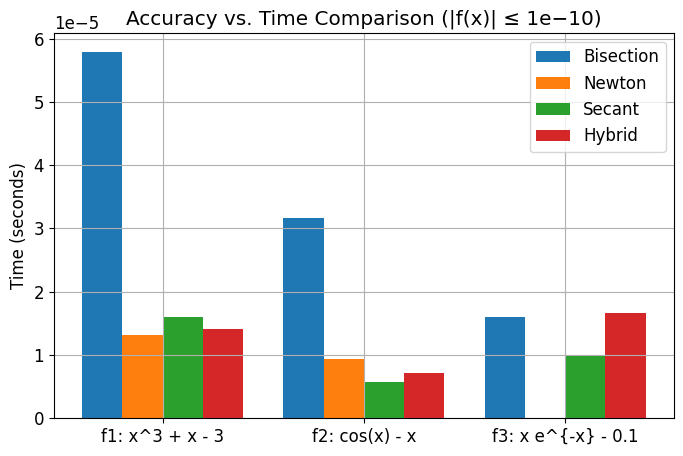

In [26]:
# Simple timing wrapper to measure time to reach |f(x)| <= tol


def time_to_tol(method_func, *args, tol_f=1e-10, **kwargs):
 t0 = time.time()
 try:
  res = method_func(*args, **kwargs)
 except Exception as e:
  return {'error': str(e), 'time': None, 'result': None}
 t1 = time.time()
 # check final f magnitude if available
 root = res.root
 ffunc = args[0] if callable(args[0]) else None
 # try to get f from closure (we expect method_func to use f directly)
 # we will not be too fancy here; instead return time and result
 return {'time': t1 - t0, 'result': res}


print('Timing helper defined.')


def run_bisection(f, df, a, b):
    return bisection(f, a, b, tol_f=1e-10)


def run_newton(f, df, a, b):
    x0 = 0.5*(a+b)
    return newton(f, df, x0, tol_f=1e-10)


def run_secant(f, df, a, b):
    return secant(f, a, b, tol_f=1e-10)


def run_hybrid(f, df, a, b):
    return hybrid_newton_bisect(f, df, a, b, tol_f=1e-10)


# Select functions f1, f2, f3 for timing study
selected = [functions[0], functions[1], functions[2]]


report = []
for (f, df, interval, name) in selected:
    a, b = interval
    results = {}
    for method_name, func in [('Bisection', run_bisection), ('Newton', run_newton), ('Secant', run_secant), ('Hybrid', run_hybrid)]:
        t0 = time.time()
        try:
            res = func(f, df, a, b)
            t1 = time.time()
            final_time = t1 - t0
            final_fx = abs(f(res.root)) if res.root is not None else None
            results[method_name] = {'time': final_time, 'iters': res.iters, '|f(x)|': final_fx}
        except Exception as e:
            results[method_name] = {'time': None, 'iters': None, 'error': str(e)}
    report.append({'function': name, 'results': results})


# Display table of results
print("Timing Study (|f(x)| <= 1e-10):\n")
for r in report:
    print(f"Function: {r['function']}")
    for method, vals in r['results'].items():
        print(f"  {method}: {vals}")
    print()


# Bar chart visualization
labels = [r['function'] for r in report]
methods = ['Bisection', 'Newton', 'Secant', 'Hybrid']


# Prepare data
x = np.arange(len(labels))
width = 0.2


fig, ax = plt.subplots(figsize=(8,5))
for i, method in enumerate(methods):
    times = [r['results'][method]['time'] if r['results'][method]['time'] else 0 for r in report]
    ax.bar(x + i*width, times, width, label=method)


ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(labels)
ax.set_ylabel('Time (seconds)')
ax.set_title('Accuracy vs. Time Comparison (|f(x)| ≤ 1e−10)')
ax.legend()
plt.grid(True)
plt.show()

Q8. Reflection & Robustness
Which method would you ship as a default? Why?

I would ship the Hybrid Newton–Bisection Method as the default solver. It combines the reliability of bisection (guaranteed convergence if a root exists in the interval) with the fast quadratic convergence of Newton near the root.

When to avoid Newton’s method?

When the derivative is zero or nearly zero (flat slope → large jumps).

When the derivative is unknown or expensive to compute.

When the initial guess is far from the root, Newton may diverge.

When to avoid Fixed-Point iteration?

When
∣
𝑔
′
(
𝑥
)
∣
≥
1
∣g
′
(x)∣≥1 — the iteration will diverge.

When the transformation function g(x) is not a contraction mapping.

How can tolerances misidentify a root near a flat spot?

If the function flattens (very small slope), |f(x)| can appear small even though x is not truly the root. Overly large tolerances may falsely report convergence. To prevent this:

Use both
∣
𝑓
(
𝑥
)
∣
∣f(x)∣ and
∣
Δ
𝑥
∣
∣Δx∣ stopping conditions.

### Inspect multiple iterations or adjust tolerance adaptively. **bold text** *italicized text*